In [48]:
import tensorflow as tf 
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense 
from tensorflow.keras.models import Sequential
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import numpy as np

In [49]:
#load MNIST data
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data() 

In [50]:
# Split the original training set into training and validation sets
x_train, x_val, y_train, y_val = train_test_split(x_train,
    y_train,
    test_size=10_000,
    random_state=42,
    stratify=y_train
)

In [51]:
# 3. Preprocess images:
#    - Convert pixel values from [0, 255] to [0, 1]
#    - Add the channel dimension required by Conv2D
x_train = x_train.astype("float32")[..., np.newaxis] / 255.0
x_val   = x_val.astype("float32")[..., np.newaxis] / 255.0
x_test  = x_test.astype("float32")[..., np.newaxis] / 255.0

# The labels are integer class IDs from 0 to 9
y_train = y_train.astype("int32")
y_val   = y_val.astype("int32")
y_test  = y_test.astype("int32")

In [52]:
#define the CNN model
model = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

In [53]:
# compile the model by specifying our optimizer and loss function.
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [55]:
# train the model 
training_history = model.fit(x_train, y_train, epochs=10, batch_size=32, validation_data=(x_val, y_val))

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9499 - loss: 0.1682 - val_accuracy: 0.9773 - val_loss: 0.0758
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9830 - loss: 0.0558 - val_accuracy: 0.9807 - val_loss: 0.0659
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9900 - loss: 0.0337 - val_accuracy: 0.9822 - val_loss: 0.0651
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9936 - loss: 0.0214 - val_accuracy: 0.9817 - val_loss: 0.0724
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9956 - loss: 0.0142 - val_accuracy: 0.9821 - val_loss: 0.0717
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9960 - loss: 0.0121 - val_accuracy: 0.9805 - val_loss: 0.0916
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9970 - loss: 0.0092 - val_accuracy: 0.9847 - val_loss: 0.0746
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9979 - loss: 0.0065 - 

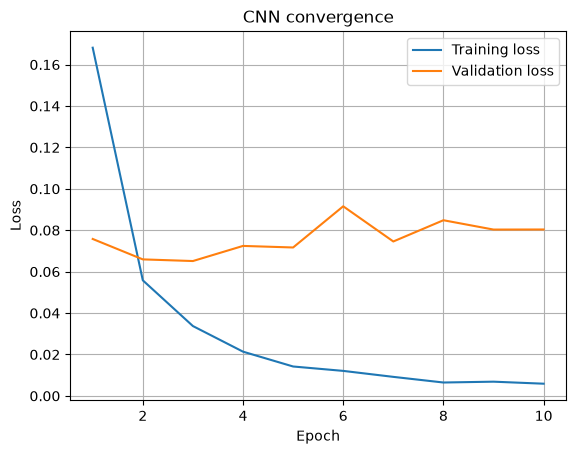

In [57]:
# plot the convergence curve
epochs = range(1, len(training_history.history["loss"]) + 1)

plt.plot(epochs, training_history.history["loss"], label="Training loss")
plt.plot(epochs, training_history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN convergence")
plt.legend()
plt.grid(True)
plt.show()

In [58]:
# test
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f'Test accuracy: {test_acc}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 980us/step - accuracy: 0.9505 - loss: 79.6052
Test accuracy: 0.9505000114440918
